
=== INITIAL STATE ===
Time step: 0
Machines: 2/2 free

DAG 0:
  Inactive : ['B', 'C', 'A']
  Active   : []
  Completed: []

DAG 1:
  Inactive : ['X', 'Y']
  Active   : []
  Completed: []

Available jobs: ['A', 'X']


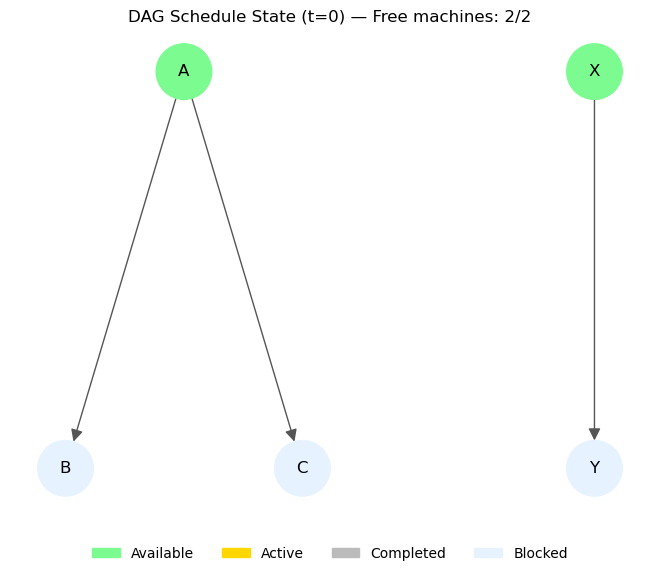


>> Starting jobs A and X (parallel)

=== AFTER STARTING A AND X ===
Time step: 0
Machines: 0/2 free

DAG 0:
  Inactive : ['B', 'C']
  Active   : ['A']
  Completed: []

DAG 1:
  Inactive : ['Y']
  Active   : ['X']
  Completed: []

Available jobs: []


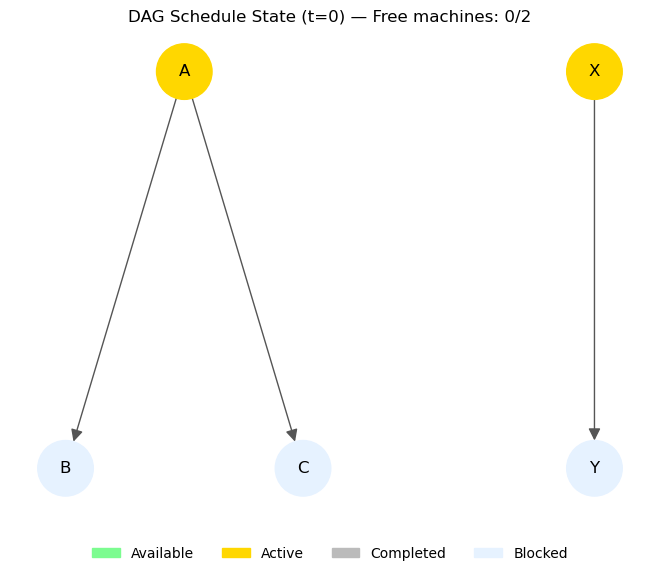


>> Advancing time by 1

=== AFTER TIME STEP 1 (A, X SHOULD COMPLETE) ===
Time step: 1
Machines: 2/2 free

DAG 0:
  Inactive : ['B', 'C']
  Active   : []
  Completed: ['A']

DAG 1:
  Inactive : ['Y']
  Active   : []
  Completed: ['X']

Available jobs: ['B', 'C', 'Y']


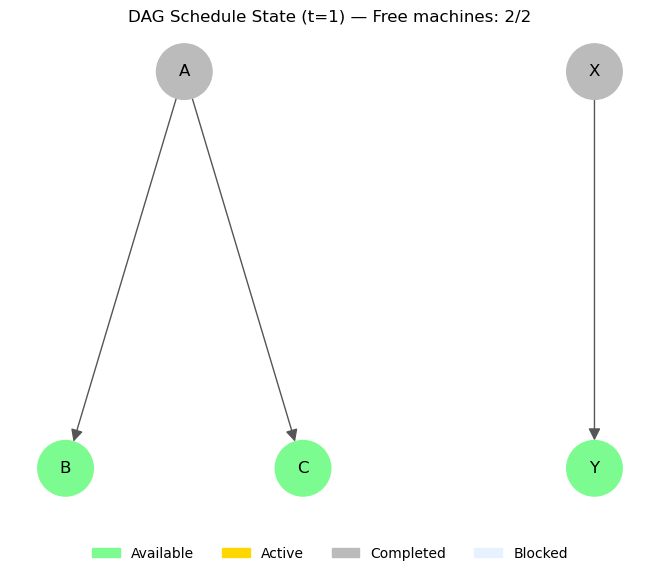


>> Starting jobs B and C (parallel)

=== AFTER STARTING B AND C ===
Time step: 1
Machines: 0/2 free

DAG 0:
  Inactive : []
  Active   : ['B', 'C']
  Completed: ['A']

DAG 1:
  Inactive : ['Y']
  Active   : []
  Completed: ['X']

Available jobs: ['Y']


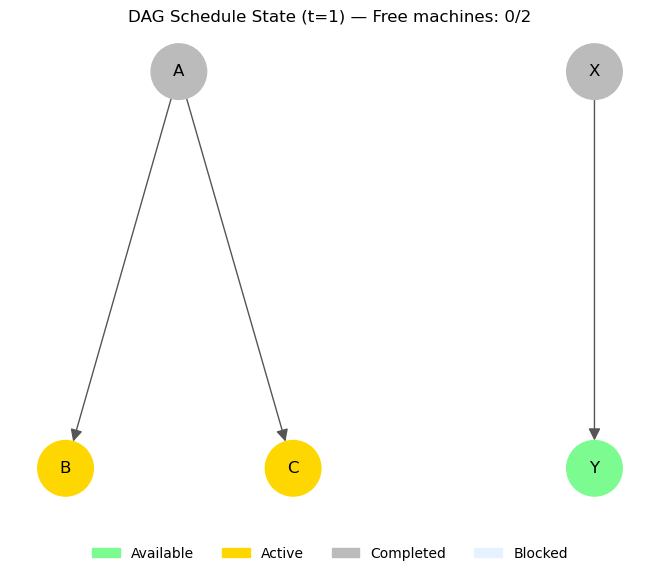


>> Advancing time by 1

=== AFTER TIME STEP 2 ===
Time step: 2
Machines: 0/2 free

DAG 0:
  Inactive : []
  Active   : ['B', 'C']
  Completed: ['A']

DAG 1:
  Inactive : ['Y']
  Active   : []
  Completed: ['X']

Available jobs: ['Y']


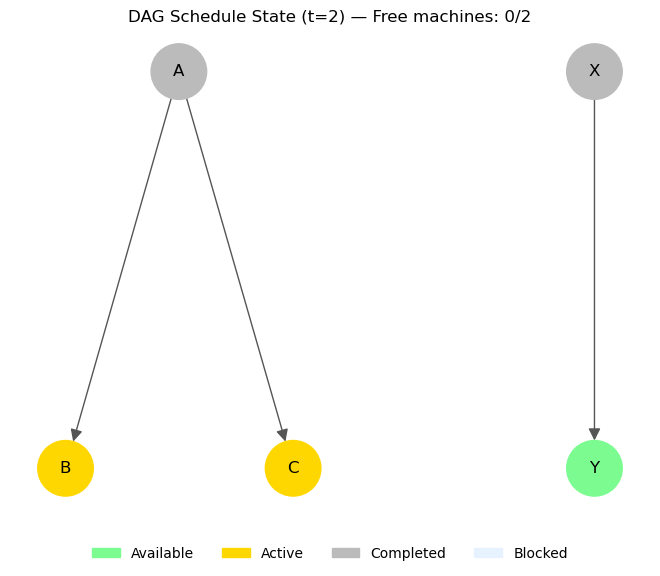


>> Advancing time by 1

=== AFTER TIME STEP 3 (B, C SHOULD COMPLETE) ===
Time step: 3
Machines: 2/2 free

DAG 0:
  Inactive : []
  Active   : []
  Completed: ['B', 'C', 'A']

DAG 1:
  Inactive : ['Y']
  Active   : []
  Completed: ['X']

Available jobs: ['Y']


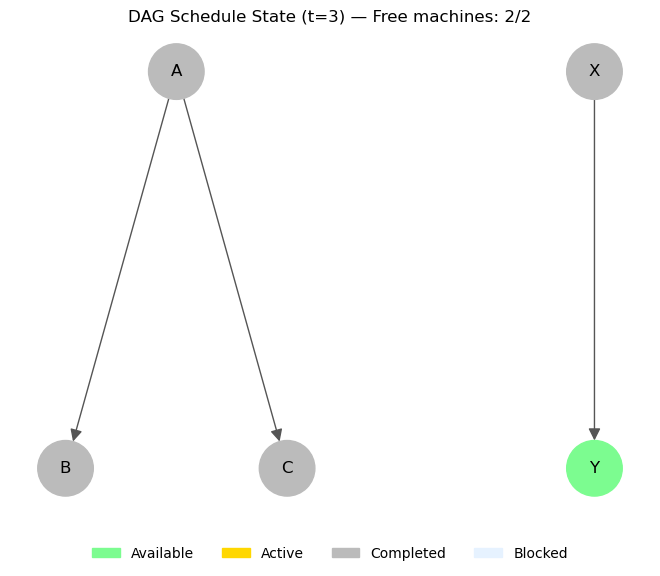


>> Starting job Y

=== AFTER STARTING Y ===
Time step: 3
Machines: 1/2 free

DAG 0:
  Inactive : []
  Active   : []
  Completed: ['B', 'C', 'A']

DAG 1:
  Inactive : []
  Active   : ['Y']
  Completed: ['X']

Available jobs: []


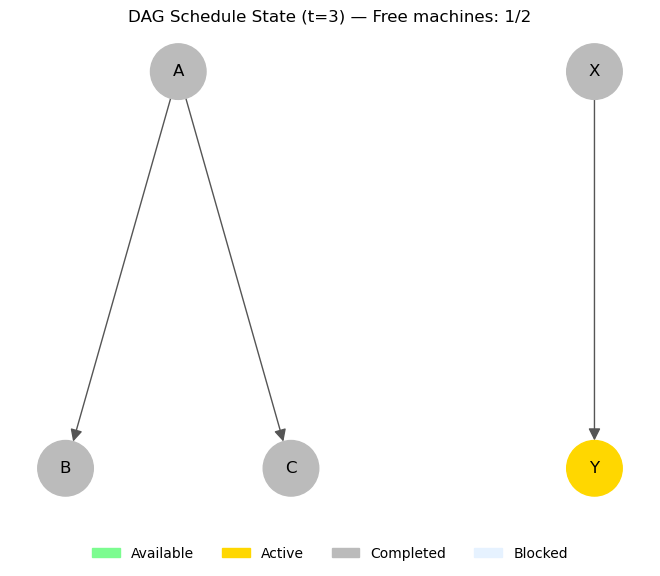


>> Advancing time by 2

=== FINAL STATE (ALL JOBS DONE) ===
Time step: 5
Machines: 2/2 free

DAG 0:
  Inactive : []
  Active   : []
  Completed: ['B', 'C', 'A']

DAG 1:
  Inactive : []
  Active   : []
  Completed: ['X', 'Y']

Available jobs: []


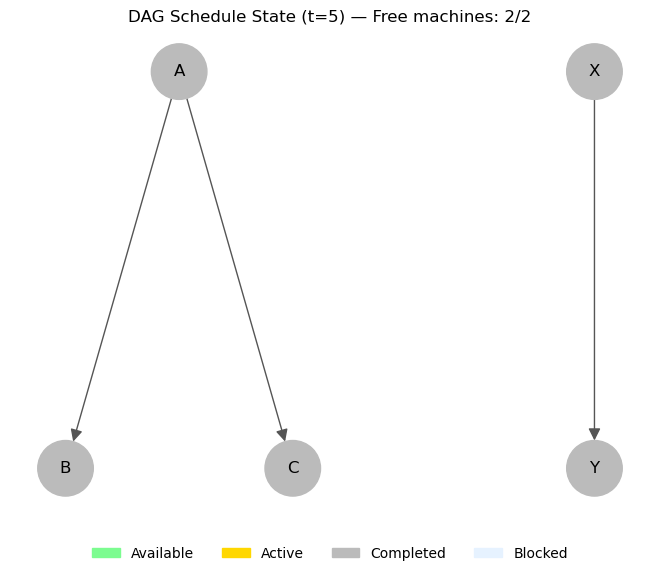

In [1]:
from job import Job
from dag import DAG
from dag_schedule import DAGSchedule


def dump_schedule_state(sched, header=None):
    if header:
        print(f"\n=== {header} ===")

    print(f"Time step: {sched.time_step}")
    print(f"Machines: {sched.free_machines}/{sched.num_machines} free")

    for i, dag in enumerate(sched.dags):
        print(f"\nDAG {i}:")
        print("  Inactive :", [j.name for j in sched.inactive[dag]])
        print("  Active   :", [j.name for j in sched.active[dag]])
        print("  Completed:", [j.name for j in sched.completed[dag]])

    avail = [job.name for _, job in sched.available()]
    print("\nAvailable jobs:", avail)


# ---------------- Define DAG jobs ----------------

A = Job("A", time_estimate=1)
B = Job("B", time_estimate=2)
C = Job("C", time_estimate=2)

X = Job("X", time_estimate=1)
Y = Job("Y", time_estimate=2)

dag1 = DAG()
dag1.add_edge(A, B)
dag1.add_edge(A, C)

dag2 = DAG()
dag2.add_edge(X, Y)


# ---------------- Initialize schedule (TWO MACHINES) ----------------

sched = DAGSchedule([dag1, dag2], num_machines=2)


# ---------------- Step 0: initial state ----------------

dump_schedule_state(sched, "INITIAL STATE")
sched.draw()


# ---------------- Step 1: start A and X in parallel ----------------

print("\n>> Starting jobs A and X (parallel)")
sched.consume(dag1, A)
sched.consume(dag2, X)

dump_schedule_state(sched, "AFTER STARTING A AND X")
sched.draw()


# ---------------- Advance time ----------------

print("\n>> Advancing time by 1")
sched.step()   # t = 1, A and X complete

dump_schedule_state(sched, "AFTER TIME STEP 1 (A, X SHOULD COMPLETE)")
sched.draw()


# ---------------- Step 2: start B and C in parallel ----------------

print("\n>> Starting jobs B and C (parallel)")
sched.consume(dag1, B)
sched.consume(dag1, C)

dump_schedule_state(sched, "AFTER STARTING B AND C")
sched.draw()


# ---------------- Advance time ----------------

print("\n>> Advancing time by 1")
sched.step()   # t = 2

dump_schedule_state(sched, "AFTER TIME STEP 2")
sched.draw()

print("\n>> Advancing time by 1")
sched.step()   # t = 3, B and C complete

dump_schedule_state(sched, "AFTER TIME STEP 3 (B, C SHOULD COMPLETE)")
sched.draw()


# ---------------- Step 3: start Y ----------------

print("\n>> Starting job Y")
sched.consume(dag2, Y)

dump_schedule_state(sched, "AFTER STARTING Y")
sched.draw()


# ---------------- Finish ----------------

print("\n>> Advancing time by 2")
sched.step()   # t = 4
sched.step()   # t = 5, Y completes

dump_schedule_state(sched, "FINAL STATE (ALL JOBS DONE)")
sched.draw()